# Part 2c. DBSCAN

DBSCAN keeps points that sit in a dense region and marks isolated points as noise.

- \(\varepsilon\) (`eps`) is the neighbourhood radius.
- `min_samples` is how many points must lie inside that radius for a point to be a core point.

A border point sits in a core neighbourhood but is not itself a core. Noise is neither. `min_samples` is tried at 8, 12, and 16. For each value, the k-distance curve supplies a knee estimate of \(\varepsilon\), and a grid around that knee is scored. Silhouette uses non-noise points only. A setting is eligible when it finds 2 to 8 clusters and marks at most 35% of reviews as noise.

## Setup, cleaning, and scaling

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures" / "dbscan"
OUT = ROOT / "outputs" / "dbscan"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RATING_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages",
    "Inflight Entertainment", "Value For Money", "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages", "Inflight Entertainment",
]
RANDOM_STATE = 42


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Question folder:", FIG.parent.name + "/" + FIG.name)
print("Data file:", DATA_PATH)

Question folder: figures/dbscan
Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {
    "True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False",
}
n_verified_fixed = int((~df["Verified"].isin(["True", "False"])).sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
n_ife_zero = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median

n_dups = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {n_verified_fixed}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {n_ife_zero}")
print(f"Duplicate reviews removed: {n_dups}")

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


In [3]:
def scale_frame(frame, cols):
    scaler = StandardScaler()
    return scaler.fit_transform(frame[cols]), scaler


X_main, scaler_main = scale_frame(df, RATING_COLS)
X_no_overall, _ = scale_frame(df, [c for c in RATING_COLS if c != "Overall Rating"])
X_service, _ = scale_frame(df, SERVICE_COLS)

scale_table = pd.DataFrame({
    "feature": RATING_COLS,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
})
display(scale_table.round(3))
scale_table.round(6).to_csv(OUT / "standard_scaler_parameters.csv", index=False)

example_raw = df.loc[0, RATING_COLS].to_numpy(dtype=float)
example_z = (example_raw - scaler_main.mean_) / scaler_main.scale_
example_check = scaler_main.transform(df.loc[[0], RATING_COLS])[0]
worked = pd.DataFrame({
    "feature": RATING_COLS,
    "raw_x": example_raw,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
    "z_manual": example_z,
    "z_scaler": example_check,
})
print("Worked standardisation for review 0. z = (x - mean) / std")
display(worked.round(4))
print("Max gap between manual z and StandardScaler:", float(np.max(np.abs(example_z - example_check))))

encoder = OneHotEncoder(sparse_output=False, dtype=np.float64)
cat_cols = ["Airline", "Class", "Type of Traveller", "Year Bin"]
X_cat = encoder.fit_transform(df[cat_cols])
X_mixed = np.hstack([X_main, X_cat])
pca_mixed = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_mixed_pca = pca_mixed.fit_transform(X_mixed)

pca_viz = PCA(n_components=2, random_state=RANDOM_STATE)
XY = pca_viz.fit_transform(X_main)
loadings = pd.DataFrame(pca_viz.components_.T, index=RATING_COLS, columns=["PC1", "PC2"])
print("PCA loadings on the 6 standardised ratings:")
display(loadings.round(3))
print(
    f"PC1 + PC2 explain {pca_viz.explained_variance_ratio_.sum():.1%} of rating variance. "
    f"Mixed-feature PCA kept {X_mixed_pca.shape[1]} components "
    f"({pca_mixed.explained_variance_ratio_.sum():.1%} variance)."
)
loadings.round(4).to_csv(OUT / "pca_loadings.csv")

,feature,mean,std
0,Seat Comfort,3.415,1.397
1,Staff Service,3.570,1.527
2,Food & Beverages,3.384,1.455
3,Inflight Entertainment,3.637,1.309
4,Value For Money,3.149,1.589
5,Overall Rating,5.632,3.523


Worked standardisation for review 0. z = (x - mean) / std


,feature,raw_x,mean,std,z_manual,z_scaler
0,Seat Comfort,4.0,3.4149,1.3969,0.4188,0.4188
1,Staff Service,4.0,3.5699,1.5273,0.2816,0.2816
2,Food & Beverages,4.0,3.3842,1.4554,0.4231,0.4231
3,Inflight Entertainment,4.0,3.6371,1.3089,0.2773,0.2773
4,Value For Money,4.0,3.1486,1.5893,0.5357,0.5357
5,Overall Rating,9.0,5.6324,3.5233,0.9558,0.9558


Max gap between manual z and StandardScaler: 0.0
PCA loadings on the 6 standardised ratings:


,PC1,PC2
Seat Comfort,0.292,0.368
Staff Service,0.309,0.318
Food & Beverages,0.249,0.473
Inflight Entertainment,0.228,0.514
Value For Money,0.591,-0.379
Overall Rating,0.597,-0.363


PC1 + PC2 explain 55.3% of rating variance. Mixed-feature PCA kept 13 components (91.5% variance).


In [4]:
def name_clusters(frame, label_col, score_col="Overall Rating"):
    # Name groups from low to high mean overall rating. Noise (-1) stays Noise.
    means = frame.loc[frame[label_col] != -1].groupby(label_col)[score_col].mean().sort_values()
    labels = list(means.index)
    if len(labels) == 2:
        pretty = ["Low satisfaction", "High satisfaction"]
    elif len(labels) == 3:
        pretty = ["Low satisfaction", "Mixed satisfaction", "High satisfaction"]
    else:
        pretty = [f"Segment {i} (low to high)" for i in range(1, len(labels) + 1)]
    mapping = {lab: pretty[i] for i, lab in enumerate(labels)}
    if (frame[label_col] == -1).any():
        mapping[-1] = "Noise"
    return mapping


def profile_clusters(frame, label_col):
    rows = []
    for lab, g in frame.groupby(label_col):
        row = {
            "cluster": lab,
            "n": len(g),
            "pct": 100 * len(g) / len(frame),
            "recommend_rate": g["Recommended"].str.lower().eq("yes").mean(),
        }
        for col in RATING_COLS:
            row[col] = g[col].mean()
        rows.append(row)
    out = pd.DataFrame(rows)
    out["name"] = out["cluster"].map(name_clusters(frame, label_col))
    return out.sort_values("Overall Rating")

## Parameter search

Highest-silhouette DBSCAN settings:


,min_samples,eps,knee_eps,n_clusters,noise_frac,silhouette
10,12,0.877,1.0320,5,0.0879,-0.0819
2,8,0.845,0.9945,4,0.0752,-0.1750
18,16,0.930,1.0941,5,0.1071,-0.1856
17,16,0.766,1.0941,6,0.2436,-0.2575
0,8,0.547,0.9945,132,0.7480,NaN
1,8,0.696,0.9945,70,0.2330,NaN
3,8,0.994,0.9945,1,0.0061,NaN
4,8,1.144,0.9945,1,0.0014,NaN


Selected DBSCAN: eps=0.877, min_samples=12, clusters=5, noise=8.8%, silhouette=-0.0819.
DBSCAN profile, including noise:


,cluster,n,pct,recommend_rate,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,name
3,2,10,0.123,0.300,2.100,5.000,4.800,1.000,3.100,4.500,Segment 1 (low to high)
0,-1,712,8.792,0.500,2.663,2.768,2.718,2.587,3.424,5.449,Noise
1,0,7354,90.813,0.531,3.494,3.650,3.452,3.741,3.119,5.644,Segment 2 (low to high)
4,3,10,0.123,0.800,1.300,1.100,1.900,5.000,3.800,7.100,Segment 3 (low to high)
5,4,5,0.062,1.000,5.000,3.400,1.200,1.000,4.000,8.600,Segment 4 (low to high)
2,1,7,0.086,1.000,1.000,2.286,1.429,4.857,5.000,9.429,Segment 5 (low to high)


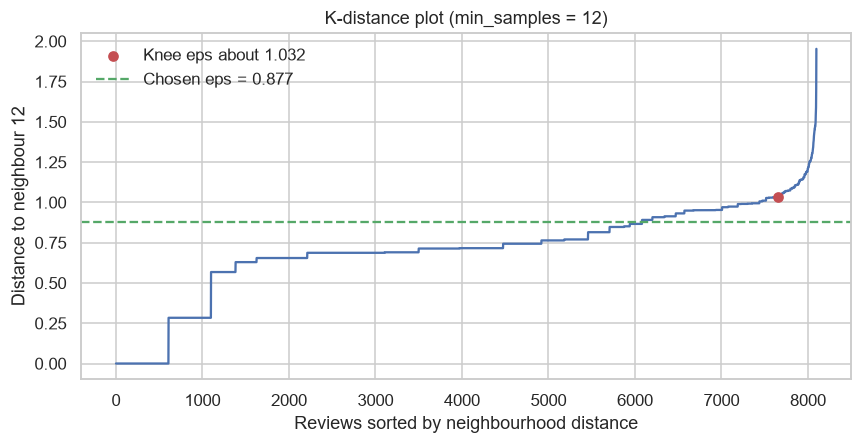

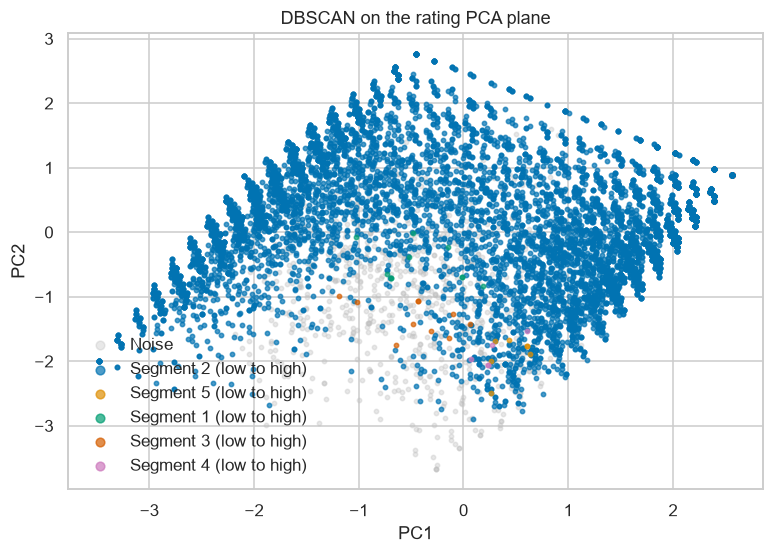

In [5]:
def knee_epsilon(sorted_dist):
    y = np.asarray(sorted_dist, dtype=float)
    x = np.linspace(0.0, 1.0, len(y))
    y_n = (y - y.min()) / (y.max() - y.min() + 1e-12)
    line = np.array([1.0, y_n[-1] - y_n[0]])
    vecs = np.column_stack([x, y_n - y_n[0]])
    cross = np.abs(line[0] * vecs[:, 1] - line[1] * vecs[:, 0])
    idx = int(np.argmax(cross))
    return float(y[idx]), idx


db_rows = []
kdist_for_plot = {}
for min_samples in [8, 12, 16]:
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X_main)
    dists = np.sort(nn.kneighbors(X_main)[0][:, -1])
    knee, knee_idx = knee_epsilon(dists)
    kdist_for_plot[min_samples] = (dists, knee, knee_idx)
    eps_grid = np.unique(np.round(np.linspace(max(0.15, knee * 0.55), knee * 1.6, 8), 3))
    for eps in eps_grid:
        labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X_main)
        n_clusters = len(set(labels) - {-1})
        noise = float(np.mean(labels == -1))
        sil = silhouette_safe(X_main, labels) if 2 <= n_clusters <= 8 and noise <= 0.50 else np.nan
        db_rows.append({
            "min_samples": min_samples,
            "eps": float(eps),
            "knee_eps": knee,
            "n_clusters": n_clusters,
            "noise_frac": noise,
            "silhouette": sil,
        })

db_table = pd.DataFrame(db_rows)
eligible = db_table[
    db_table["silhouette"].notna()
    & db_table["n_clusters"].between(2, 8)
    & (db_table["noise_frac"] <= 0.35)
].copy()
if eligible.empty:
    eligible = db_table[db_table["silhouette"].notna()].copy()
print("Highest-silhouette DBSCAN settings:")
display(db_table.sort_values("silhouette", ascending=False).head(8).round(4))
db_table.to_csv(OUT / "dbscan_grid.csv", index=False)

best_db = eligible.sort_values(["silhouette", "noise_frac"], ascending=[False, True]).iloc[0]
db_eps = float(best_db["eps"])
db_min = int(best_db["min_samples"])
df["dbscan"] = DBSCAN(eps=db_eps, min_samples=db_min).fit_predict(X_main)
db_sil = silhouette_safe(X_main, df["dbscan"])
db_noise = float((df["dbscan"] == -1).mean())
db_n = len(set(df["dbscan"]) - {-1})
print(
    f"Selected DBSCAN: eps={db_eps:.3f}, min_samples={db_min}, "
    f"clusters={db_n}, noise={db_noise:.1%}, silhouette={db_sil:.4f}."
)

d_profile = profile_clusters(df, "dbscan")
d_names = name_clusters(df, "dbscan")
df["dbscan_name"] = df["dbscan"].map(d_names)
print("DBSCAN profile, including noise:")
display(d_profile.round(3))
d_profile.round(3).to_csv(OUT / "dbscan_profile.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
dists, knee, knee_idx = kdist_for_plot[db_min]
ax.plot(dists, color="#4C72B0")
ax.scatter([knee_idx], [knee], color="#C44E52", zorder=3, label=f"Knee eps about {knee:.3f}")
ax.axhline(db_eps, color="#55A868", ls="--", label=f"Chosen eps = {db_eps:.3f}")
ax.set_xlabel("Reviews sorted by neighbourhood distance")
ax.set_ylabel(f"Distance to neighbour {db_min}")
ax.set_title(f"K-distance plot (min_samples = {db_min})")
ax.legend(frameon=False)
save_fig(fig, "kdistance.png")

fig, ax = plt.subplots(figsize=(7.2, 5.2))
palette = sns.color_palette("colorblind", n_colors=max(db_n, 1))
color_i = 0
for lab in sorted(df["dbscan"].unique()):
    m = df["dbscan"].to_numpy() == lab
    if lab == -1:
        ax.scatter(XY[m, 0], XY[m, 1], s=8, alpha=0.35, color="0.75", label=d_names[lab])
    else:
        ax.scatter(XY[m, 0], XY[m, 1], s=8, alpha=0.7, color=palette[color_i % len(palette)], label=d_names[lab])
        color_i += 1
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("DBSCAN on the rating PCA plane")
ax.legend(markerscale=2, frameon=False)
save_fig(fig, "dbscan_pca.png")

## Part 2c answer

The selected `eps`, `min_samples`, cluster count, noise share, and silhouette are printed with the k-distance plot. A low or negative silhouette means the dense region is one cloud rather than separated blobs. Tiny extra clusters, if they appear, are pockets of a few similar score patterns, not a second large passenger segment.